Step 1: Mount Google Drive

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


Step 2: Install the required libraries

In [ ]:
%pip install -q -U \
    transformers \
    accelerate \
    "bitsandbytes>=0.46.1" \
    "pandas==2.2.3" \
    "pillow==11.3.0" \
    "huggingface_hub>=1.32,<2.0" \
    nibabel

Step 3: Verify the installation

In [ ]:
import pandas as pd
import PIL
import nibabel as nib
import huggingface_hub
import transformers
import accelerate
import bitsandbytes

print("pandas:", pd.__version__)
print("Pillow:", PIL.__version__)
print("nibabel:", nib.__version__)
print("huggingface_hub:", huggingface_hub.__version__)
print("transformers:", transformers.__version__)
print("accelerate:", accelerate.__version__)
print("bitsandbytes:", bitsandbytes.__version__)

print("\nCAMUS dependencies loaded successfully!")

pandas: 2.2.3
Pillow: 11.3.0
nibabel: 5.4.2
huggingface_hub: 1.33.0
transformers: 5.20.2
accelerate: 1.15.0
bitsandbytes: 0.50.2

CAMUS dependencies loaded successfully!


Step 4: Log in to Hugging Face

In [ ]:
from google.colab import userdata
from huggingface_hub import login, whoami

token = userdata.get("HF_TOKEN")

login(token=token)

print("Logged in as:", whoami()["name"])

Logged in as: siyonanaik


Step 5: Locate the CAMUS dataset in Google Drive

In [ ]:
from pathlib import Path

project_root = Path(
    "/content/drive/MyDrive/Ultrasound_Project-Siyona"
)

print("Project folder exists:", project_root.exists())
print("\nItems inside the project folder:")

for item in sorted(project_root.iterdir()):
    print("-", item.name)

Project folder exists: True

Items inside the project folder:
- data
- prompts
- results


Step 6: Inspect the data folder

In [ ]:
data_root = project_root / "data"

print("Data folder:", data_root)
print("Data folder exists:", data_root.exists())

print("\nItems inside the data folder:")

for item in sorted(data_root.iterdir()):
    print("-", item.name)

Data folder: /content/drive/MyDrive/Ultrasound_Project-Siyona/data
Data folder exists: True

Items inside the data folder:
- busi_manifest.csv
- processed
- raw
- splits


Step 8: Reinspect the raw-data folder

In [ ]:
raw_data_root = data_root / "raw"

print("Items inside the raw-data folder:")

for item in sorted(raw_data_root.iterdir()):
    print("-", item.name)

Items inside the raw-data folder:
- BUSI
- CAMUS


Step 9: Check what is inside the CAMUS folder

In [ ]:
camus_root = raw_data_root / "CAMUS"

print("CAMUS folder:", camus_root)
print("CAMUS folder exists:", camus_root.exists())

print("\nItems inside the CAMUS folder:")

for item in sorted(camus_root.iterdir()):
    print("-", item.name)

CAMUS folder: /content/drive/MyDrive/Ultrasound_Project-Siyona/data/raw/CAMUS
CAMUS folder exists: True

Items inside the CAMUS folder:
- CAMUS_public
- CAMUS_public.zip


Step 10: Extract the CAMUS ZIP archive

In [ ]:
import zipfile

camus_zip_path = (
    camus_root /
    "CAMUS_public.zip"
)

camus_public_root = (
    camus_root /
    "CAMUS_public"
)

required_nifti_folder = (
    camus_public_root /
    "database_nifti"
)

required_split_folder = (
    camus_public_root /
    "database_split"
)

if (
    required_nifti_folder.exists()
    and required_split_folder.exists()
):
    print(
        "CAMUS dataset is already extracted."
    )
    print(
        "Skipping ZIP extraction."
    )
else:
    print(
        "Extracting CAMUS dataset..."
    )

    with zipfile.ZipFile(
        camus_zip_path,
        "r"
    ) as zip_file:
        zip_file.extractall(
            camus_root
        )

    print(
        "Extraction completed!"
    )

CAMUS dataset is already extracted.
Skipping ZIP extraction.


Step 11: Inspect the extracted dataset

In [ ]:
camus_public_root = camus_root / "CAMUS_public"

print("Extracted CAMUS folder:")
print(camus_public_root)

print(
    "Extracted folder exists:",
    camus_public_root.exists()
)

print("\nItems inside CAMUS_public:")

for item in sorted(camus_public_root.iterdir()):
    print("-", item.name)

Extracted CAMUS folder:
/content/drive/MyDrive/Ultrasound_Project-Siyona/data/raw/CAMUS/CAMUS_public
Extracted folder exists: True

Items inside CAMUS_public:
- database_nifti
- database_split
- jupyter


Step 12: Validate the image and split folders

In [ ]:
camus_nifti_root = (
    camus_public_root /
    "database_nifti"
)

camus_split_root = (
    camus_public_root /
    "database_split"
)

patient_folders = sorted(
    camus_nifti_root.glob("patient*")
)

split_files = sorted(
    camus_split_root.glob("*.txt")
)

print(
    "NIfTI folder exists:",
    camus_nifti_root.exists()
)

print(
    "Split folder exists:",
    camus_split_root.exists()
)

print(
    "\nNumber of patient folders:",
    len(patient_folders)
)

print("\nSplit files:")

for split_file in split_files:
    print("-", split_file.name)

print("\nFirst patient folder:")
print(patient_folders[0])

NIfTI folder exists: True
Split folder exists: True

Number of patient folders: 500

Split files:
- information.txt
- subgroup_testing.txt
- subgroup_training.txt
- subgroup_validation.txt

First patient folder:
/content/drive/MyDrive/Ultrasound_Project-Siyona/data/raw/CAMUS/CAMUS_public/database_nifti/patient0001


Step 13: Inspect one patient’s files and metadata

In [ ]:
sample_patient_folder = patient_folders[0]

print("Sample patient:")
print(sample_patient_folder.name)

print("\nFiles inside the patient folder:")

for file_path in sorted(
    sample_patient_folder.iterdir()
):
    print("-", file_path.name)

for view in ["2CH", "4CH"]:
    info_path = (
        sample_patient_folder /
        f"Info_{view}.cfg"
    )

    print(f"\nContents of {info_path.name}:")
    print(info_path.read_text(encoding="utf-8"))

Sample patient:
patient0001

Files inside the patient folder:
- Info_2CH.cfg
- Info_4CH.cfg
- MANDATORY_CITATION.md
- patient0001_2CH_ED.nii.gz
- patient0001_2CH_ED_gt.nii.gz
- patient0001_2CH_ES.nii.gz
- patient0001_2CH_ES_gt.nii.gz
- patient0001_2CH_half_sequence.nii.gz
- patient0001_2CH_half_sequence_gt.nii.gz
- patient0001_4CH_ED.nii.gz
- patient0001_4CH_ED_gt.nii.gz
- patient0001_4CH_ES.nii.gz
- patient0001_4CH_ES_gt.nii.gz
- patient0001_4CH_half_sequence.nii.gz
- patient0001_4CH_half_sequence_gt.nii.gz

Contents of Info_2CH.cfg:
ED: 1
ES: 18
NbFrame: 18
Sex: F
Age: 56
ImageQuality: Good
EF: 54
FrameRate: 48.4


Contents of Info_4CH.cfg:
ED: 1
ES: 20
NbFrame: 20
Sex: F
Age: 56
ImageQuality: Good
EF: 54
FrameRate: 48.4



Step 14: Inspect the official validation split

In [ ]:
validation_split_path = (
    camus_split_root /
    "subgroup_validation.txt"
)

validation_patients = [
    line.strip()
    for line in validation_split_path.read_text(
        encoding="utf-8"
    ).splitlines()
    if line.strip()
]

print("Validation split file:")
print(validation_split_path)

print(
    "\nNumber of validation patients:",
    len(validation_patients)
)

print("\nFirst 10 validation patients:")

for patient_id in validation_patients[:10]:
    print("-", patient_id)

Validation split file:
/content/drive/MyDrive/Ultrasound_Project-Siyona/data/raw/CAMUS/CAMUS_public/database_split/subgroup_validation.txt

Number of validation patients: 50

First 10 validation patients:
- patient0200
- patient0206
- patient0230
- patient0232
- patient0233
- patient0235
- patient0236
- patient0244
- patient0245
- patient0247


Step 15: Build a validation metadata table

In [ ]:
import pandas as pd

def read_camus_info(info_path):
    metadata = {}

    for line in info_path.read_text(
        encoding="utf-8"
    ).splitlines():
        if ":" in line:
            key, value = line.split(":", 1)
            metadata[key.strip()] = value.strip()

    return metadata


camus_metadata_rows = []

view_mapping = {
    "2CH": "A2C",
    "4CH": "A4C"
}

for patient_id in validation_patients:
    patient_folder = (
        camus_nifti_root /
        patient_id
    )

    for file_view, output_view in view_mapping.items():
        info_path = (
            patient_folder /
            f"Info_{file_view}.cfg"
        )

        metadata = read_camus_info(info_path)

        camus_metadata_rows.append({
            "patient_id": patient_id,
            "file_view": file_view,
            "view_label": output_view,
            "image_quality": metadata["ImageQuality"].lower(),
            "ed_frame_number": int(metadata["ED"]),
            "es_frame_number": int(metadata["ES"]),
            "ed_nifti_path": str(
                patient_folder /
                f"{patient_id}_{file_view}_ED.nii.gz"
            ),
            "es_nifti_path": str(
                patient_folder /
                f"{patient_id}_{file_view}_ES.nii.gz"
            )
        })

camus_validation_metadata_df = pd.DataFrame(
    camus_metadata_rows
)

print(
    "Patient-view cases:",
    len(camus_validation_metadata_df)
)

print("\nCases by view and image quality:")

display(
    pd.crosstab(
        camus_validation_metadata_df["view_label"],
        camus_validation_metadata_df["image_quality"]
    )
)

display(camus_validation_metadata_df.head())

Patient-view cases: 100

Cases by view and image quality:


image_quality,good,medium,poor
view_label,,,
A2C,23,19,8
A4C,27,20,3


,patient_id,file_view,view_label,image_quality,ed_frame_number,es_frame_number,ed_nifti_path,es_nifti_path
0,patient0200,2CH,A2C,good,1,19,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...
1,patient0200,4CH,A4C,good,1,22,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...
2,patient0206,2CH,A2C,good,1,20,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...
3,patient0206,4CH,A4C,good,1,22,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...
4,patient0230,2CH,A2C,good,1,18,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...


Step 16: Select 10 balanced patient-view cases

In [ ]:
import numpy as np

CAMUS_SELECTION_SEED = 42
rng = np.random.default_rng(
    CAMUS_SELECTION_SEED
)

selection_plan = [
    ("A4C", "poor", 1),
    ("A2C", "poor", 1),
    ("A2C", "good", 2),
    ("A2C", "medium", 2),
    ("A4C", "good", 2),
    ("A4C", "medium", 2)
]

selected_rows = []
selected_patients = set()

for view_label, image_quality, number_needed in selection_plan:
    candidates = camus_validation_metadata_df[
        (
            camus_validation_metadata_df["view_label"]
            == view_label
        )
        & (
            camus_validation_metadata_df["image_quality"]
            == image_quality
        )
        & (
            ~camus_validation_metadata_df["patient_id"]
            .isin(selected_patients)
        )
    ].sort_values("patient_id")

    selected_indices = rng.choice(
        candidates.index.to_numpy(),
        size=number_needed,
        replace=False
    )

    selected_group = (
        camus_validation_metadata_df
        .loc[selected_indices]
    )

    selected_rows.append(selected_group)

    selected_patients.update(
        selected_group["patient_id"]
    )

selected_cases_df = (
    pd.concat(selected_rows)
    .sort_values(
        ["view_label", "image_quality", "patient_id"]
    )
    .reset_index(drop=True)
)

print(
    "Selected patient-view cases:",
    len(selected_cases_df)
)

print(
    "Unique patients:",
    selected_cases_df["patient_id"].nunique()
)

print("\nSelected cases by view and quality:")

display(
    pd.crosstab(
        selected_cases_df["view_label"],
        selected_cases_df["image_quality"]
    )
)

display(
    selected_cases_df[
        [
            "patient_id",
            "view_label",
            "image_quality"
        ]
    ]
)

Selected patient-view cases: 10
Unique patients: 10

Selected cases by view and quality:


image_quality,good,medium,poor
view_label,,,
A2C,2,2,1
A4C,2,2,1


,patient_id,view_label,image_quality
0,patient0249,A2C,good
1,patient0256,A2C,good
2,patient0265,A2C,medium
3,patient0298,A2C,medium
4,patient0333,A2C,poor
5,patient0230,A4C,good
6,patient0233,A4C,good
7,patient0303,A4C,medium
8,patient0315,A4C,medium
9,patient0292,A4C,poor


Step 17: Create the 20-image manifest

In [ ]:
camus_processed_folder = (
    data_root /
    "processed" /
    "camus_development_20"
)

camus_processed_folder.mkdir(
    parents=True,
    exist_ok=True
)

camus_manifest_rows = []

phase_settings = [
    (
        "ED",
        "end diastole",
        "ed_nifti_path"
    ),
    (
        "ES",
        "end systole",
        "es_nifti_path"
    )
]

for _, case in selected_cases_df.iterrows():
    for phase_code, phase_label, path_column in phase_settings:
        image_id = (
            f"{case['patient_id']}_"
            f"{case['file_view']}_"
            f"{phase_code}.png"
        )

        png_path = (
            camus_processed_folder /
            image_id
        )

        camus_manifest_rows.append({
            "image_id": image_id,
            "patient_id": case["patient_id"],
            "view_label": case["view_label"],
            "file_view": case["file_view"],
            "image_quality": case["image_quality"],
            "phase_code": phase_code,
            "phase_label": phase_label,
            "source_nifti_path": case[path_column],
            "image_path": str(png_path),
            "official_split": "validation",
            "dataset_selection_seed":
                CAMUS_SELECTION_SEED
        })

camus_manifest_df = pd.DataFrame(
    camus_manifest_rows
)

print(
    "Manifest rows:",
    len(camus_manifest_df)
)

print("\nImages by view:")
print(
    camus_manifest_df[
        "view_label"
    ].value_counts()
)

print("\nImages by cardiac phase:")
print(
    camus_manifest_df[
        "phase_label"
    ].value_counts()
)

print("\nImages by quality:")
print(
    camus_manifest_df[
        "image_quality"
    ].value_counts()
)

display(camus_manifest_df.head())

Manifest rows: 20

Images by view:
view_label
A2C    10
A4C    10
Name: count, dtype: int64

Images by cardiac phase:
phase_label
end diastole    10
end systole     10
Name: count, dtype: int64

Images by quality:
image_quality
good      8
medium    8
poor      4
Name: count, dtype: int64


,image_id,patient_id,view_label,file_view,image_quality,phase_code,phase_label,source_nifti_path,image_path,official_split,dataset_selection_seed
0,patient0249_2CH_ED.png,patient0249,A2C,2CH,good,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
1,patient0249_2CH_ES.png,patient0249,A2C,2CH,good,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
2,patient0256_2CH_ED.png,patient0256,A2C,2CH,good,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
3,patient0256_2CH_ES.png,patient0256,A2C,2CH,good,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
4,patient0265_2CH_ED.png,patient0265,A2C,2CH,medium,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42


Step 18: Save the fixed manifest

In [ ]:
camus_manifest_path = (
    data_root /
    "splits" /
    "camus_development_20.csv"
)

source_files_exist = (
    camus_manifest_df[
        "source_nifti_path"
    ]
    .apply(
        lambda path: Path(path).exists()
    )
)

print(
    "Existing source NIfTI files:",
    source_files_exist.sum(),
    "/",
    len(source_files_exist)
)

if not source_files_exist.all():
    raise FileNotFoundError(
        "One or more source NIfTI files are missing."
    )

camus_manifest_df.to_csv(
    camus_manifest_path,
    index=False
)

print("\nSaved CAMUS manifest to:")
print(camus_manifest_path)

print(
    "\nManifest rows saved:",
    len(camus_manifest_df)
)

Existing source NIfTI files: 20 / 20

Saved CAMUS manifest to:
/content/drive/MyDrive/Ultrasound_Project-Siyona/data/splits/camus_development_20.csv

Manifest rows saved: 20


In [ ]:
import pandas as pd

# Let's inspect the saved manifest file
manifest_path = "/content/drive/MyDrive/Ultrasound_Project-Siyona/data/splits/camus_development_20.csv"
df_manifest = pd.read_csv(manifest_path)
print("Number of rows in saved manifest:", len(df_manifest))
display(df_manifest)

Number of rows in saved manifest: 20


,image_id,patient_id,view_label,file_view,image_quality,phase_code,phase_label,source_nifti_path,image_path,official_split,dataset_selection_seed
0,patient0249_2CH_ED.png,patient0249,A2C,2CH,good,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
1,patient0249_2CH_ES.png,patient0249,A2C,2CH,good,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
2,patient0256_2CH_ED.png,patient0256,A2C,2CH,good,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
3,patient0256_2CH_ES.png,patient0256,A2C,2CH,good,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
4,patient0265_2CH_ED.png,patient0265,A2C,2CH,medium,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
5,patient0265_2CH_ES.png,patient0265,A2C,2CH,medium,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
6,patient0298_2CH_ED.png,patient0298,A2C,2CH,medium,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
7,patient0298_2CH_ES.png,patient0298,A2C,2CH,medium,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
8,patient0333_2CH_ED.png,patient0333,A2C,2CH,poor,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
9,patient0333_2CH_ES.png,patient0333,A2C,2CH,poor,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42


In [ ]:
import pandas as pd

# Let's inspect the saved manifest file
manifest_path = "/content/drive/MyDrive/Ultrasound_Project-Siyona/data/splits/camus_development_20.csv"
df_manifest = pd.read_csv(manifest_path)
print("Number of rows in saved manifest:", len(df_manifest))
display(df_manifest)

Number of rows in saved manifest: 20


,image_id,patient_id,view_label,file_view,image_quality,phase_code,phase_label,source_nifti_path,image_path,official_split,dataset_selection_seed
0,patient0249_2CH_ED.png,patient0249,A2C,2CH,good,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
1,patient0249_2CH_ES.png,patient0249,A2C,2CH,good,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
2,patient0256_2CH_ED.png,patient0256,A2C,2CH,good,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
3,patient0256_2CH_ES.png,patient0256,A2C,2CH,good,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
4,patient0265_2CH_ED.png,patient0265,A2C,2CH,medium,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
5,patient0265_2CH_ES.png,patient0265,A2C,2CH,medium,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
6,patient0298_2CH_ED.png,patient0298,A2C,2CH,medium,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
7,patient0298_2CH_ES.png,patient0298,A2C,2CH,medium,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
8,patient0333_2CH_ED.png,patient0333,A2C,2CH,poor,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
9,patient0333_2CH_ES.png,patient0333,A2C,2CH,poor,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42


Step 19: Open and inspect one NIfTI image

Image ID: patient0249_2CH_ED.png
True view: A2C
True quality: good
True phase: end diastole

Original NIfTI shape: (551, 454)
Squeezed array shape: (551, 454)
Minimum pixel value: 0.0
Maximum pixel value: 255.0


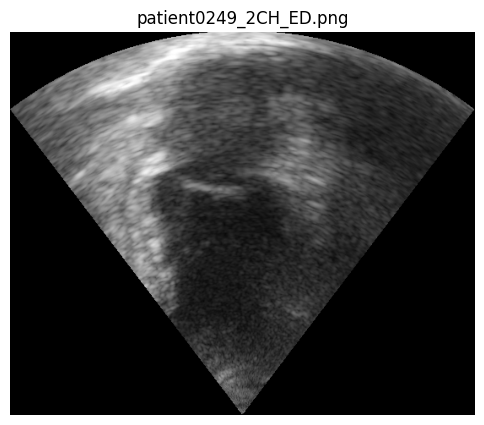

In [ ]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

sample_nifti_path = Path(
    camus_manifest_df.iloc[0][
        "source_nifti_path"
    ]
)

sample_nifti = nib.load(
    sample_nifti_path
)

sample_array = np.asarray(
    sample_nifti.get_fdata()
).squeeze()

print("Image ID:", camus_manifest_df.iloc[0]["image_id"])
print("True view:", camus_manifest_df.iloc[0]["view_label"])
print("True quality:", camus_manifest_df.iloc[0]["image_quality"])
print("True phase:", camus_manifest_df.iloc[0]["phase_label"])

print("\nOriginal NIfTI shape:", sample_nifti.shape)
print("Squeezed array shape:", sample_array.shape)
print("Minimum pixel value:", sample_array.min())
print("Maximum pixel value:", sample_array.max())

plt.figure(figsize=(6, 6))

plt.imshow(
    sample_array.T,
    cmap="gray",
    origin="lower"
)

plt.title(
    camus_manifest_df.iloc[0]["image_id"]
)

plt.axis("off")
plt.show()

Step 20: Remove the vertical flip

Ultrasound NIfTI data is often stored with coordinates that appear flipped, rotated, or mirrored when opened in standard software. During the conversion to PNG, we transpose the pixel matrix (image_array.T) to ensure the ultrasound sector is oriented correctly with its narrow point at the top before it is passed to the model.

Corrected test PNG saved to:
/content/drive/MyDrive/Ultrasound_Project-Siyona/data/processed/camus_development_20/patient0249_2CH_ED.png
PNG size: (551, 454)
PNG mode: L


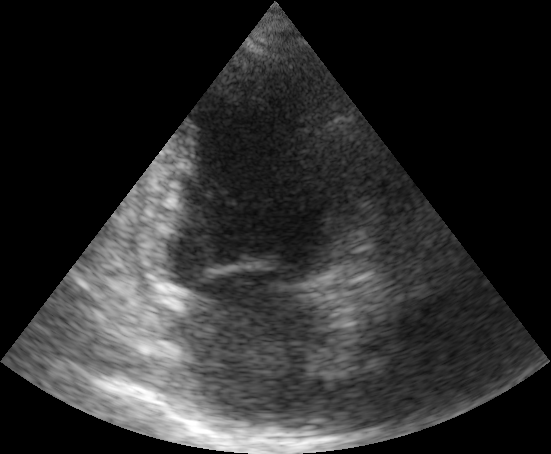

In [ ]:
from PIL import Image

def convert_nifti_to_png(
    nifti_path,
    png_path
):
    nifti_image = nib.load(
        str(nifti_path)
    )

    image_array = np.asarray(
        nifti_image.get_fdata()
    ).squeeze()

    if image_array.ndim != 2:
        raise ValueError(
            "Expected a 2D image, "
            f"but received shape {image_array.shape}"
        )

    image_array = np.clip(
        image_array,
        0,
        255
    ).astype(np.uint8)

    # Transpose the NIfTI array so the ultrasound
    # sector has its narrow point at the top.
    png_array = image_array.T

    png_image = Image.fromarray(
        png_array
    )

    png_path = Path(png_path)

    png_path.parent.mkdir(
        parents=True,
        exist_ok=True
    )

    png_image.save(png_path)

    return png_path


test_png_path = convert_nifti_to_png(
    camus_manifest_df.iloc[0][
        "source_nifti_path"
    ],
    camus_manifest_df.iloc[0][
        "image_path"
    ]
)

print("Corrected test PNG saved to:")
print(test_png_path)

test_png = Image.open(test_png_path)

print("PNG size:", test_png.size)
print("PNG mode:", test_png.mode)

display(test_png)

Step 21: Convert all 20 NIfTI images to PNG

MedGemma is a Vision-Language Model built to accept standard 2D image formats (like PNG or JPEG) as visual input. It cannot directly read or process raw 3D/4D clinical neuroimaging or cardiology files like NIfTI.

In [ ]:
converted_paths = []

for position, (_, row) in enumerate(
    camus_manifest_df.iterrows(),
    start=1
):
    converted_path = convert_nifti_to_png(
        row["source_nifti_path"],
        row["image_path"]
    )

    converted_paths.append(
        converted_path
    )

    print(
        f"Converted {position}/20: "
        f"{row['image_id']}"
    )

converted_files_exist = [
    Path(path).exists()
    for path in camus_manifest_df[
        "image_path"
    ]
]

print(
    "\nExisting PNG files:",
    sum(converted_files_exist),
    "/",
    len(converted_files_exist)
)

print(
    "Conversion completed successfully!"
)

Converted 1/20: patient0249_2CH_ED.png
Converted 2/20: patient0249_2CH_ES.png
Converted 3/20: patient0256_2CH_ED.png
Converted 4/20: patient0256_2CH_ES.png
Converted 5/20: patient0265_2CH_ED.png
Converted 6/20: patient0265_2CH_ES.png
Converted 7/20: patient0298_2CH_ED.png
Converted 8/20: patient0298_2CH_ES.png
Converted 9/20: patient0333_2CH_ED.png
Converted 10/20: patient0333_2CH_ES.png
Converted 11/20: patient0230_4CH_ED.png
Converted 12/20: patient0230_4CH_ES.png
Converted 13/20: patient0233_4CH_ED.png
Converted 14/20: patient0233_4CH_ES.png
Converted 15/20: patient0303_4CH_ED.png
Converted 16/20: patient0303_4CH_ES.png
Converted 17/20: patient0315_4CH_ED.png
Converted 18/20: patient0315_4CH_ES.png
Converted 19/20: patient0292_4CH_ED.png
Converted 20/20: patient0292_4CH_ES.png

Existing PNG files: 20 / 20
Conversion completed successfully!


Step 22: Visually check all converted images

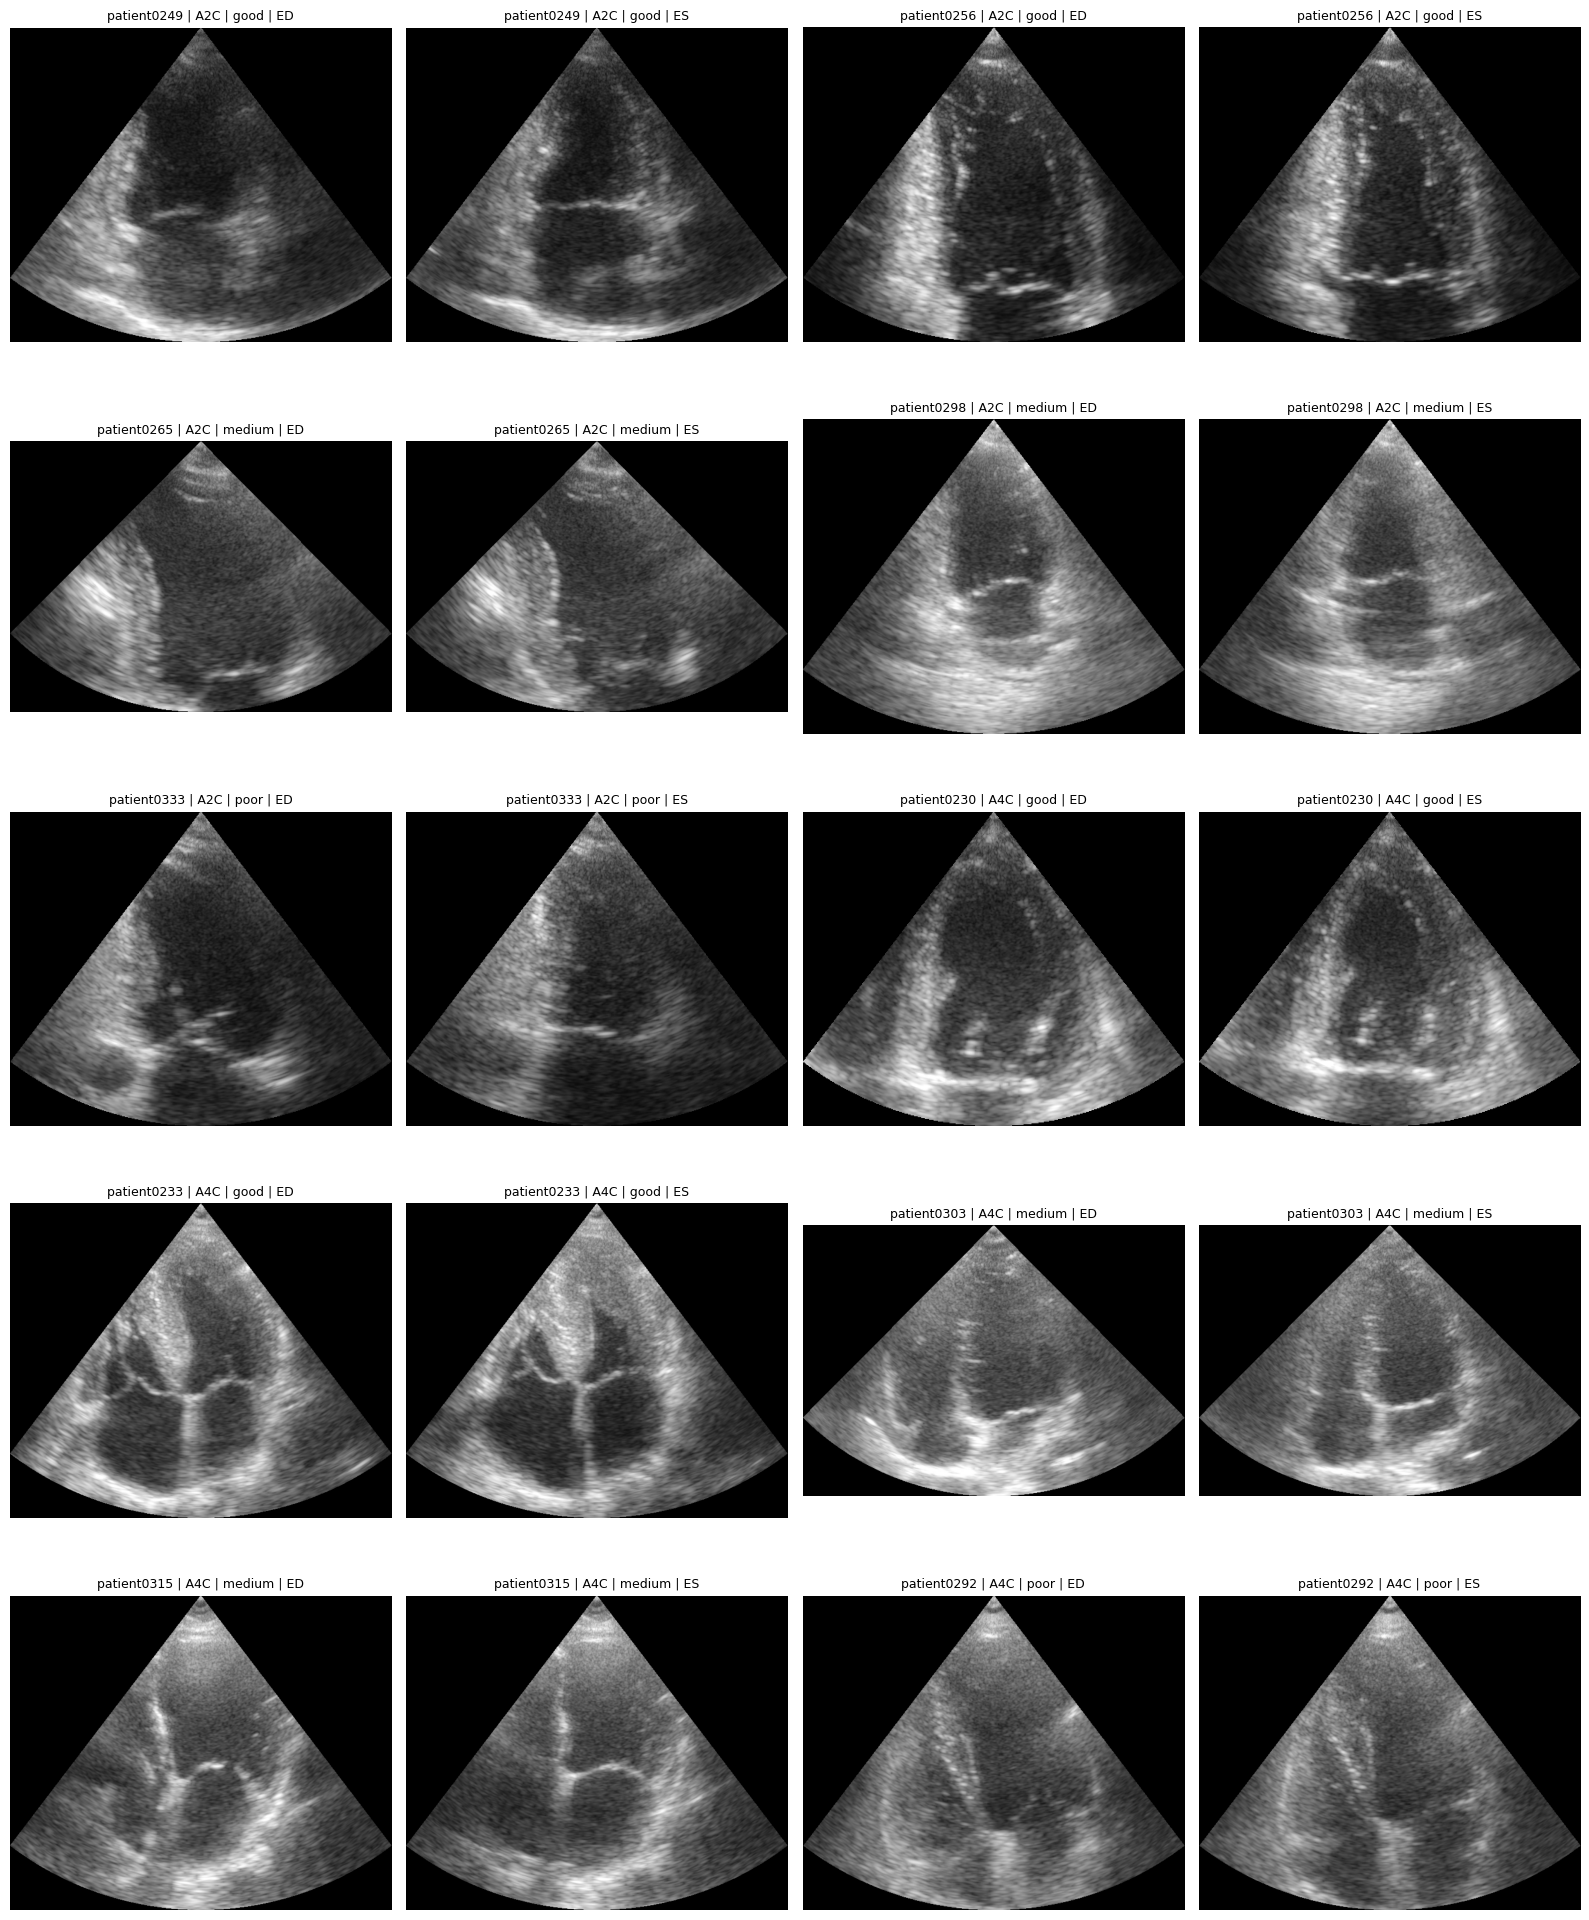

In [ ]:
fig, axes = plt.subplots(
    5,
    4,
    figsize=(16, 20)
)

axes = axes.flatten()

for axis, (_, row) in zip(
    axes,
    camus_manifest_df.iterrows()
):
    image = Image.open(
        row["image_path"]
    )

    axis.imshow(
        image,
        cmap="gray"
    )

    axis.set_title(
        f"{row['patient_id']} | "
        f"{row['view_label']} | "
        f"{row['image_quality']} | "
        f"{row['phase_code']}",
        fontsize=9
    )

    axis.axis("off")

plt.tight_layout()
plt.show()

Step 23: Create the CAMUS prompt folder

In [ ]:
camus_prompt_folder = (
    project_root /
    "prompts" /
    "camus"
)

camus_prompt_folder.mkdir(
    parents=True,
    exist_ok=True
)

print("CAMUS prompt folder created:")
print(camus_prompt_folder)

CAMUS prompt folder created:
/content/drive/MyDrive/Ultrasound_Project-Siyona/prompts/camus


Step 24: Create the multi-task classification prompt

In [ ]:
CAMUS_PROMPT = """Review this single 2D echocardiographic ultrasound image.

Determine exactly one label for each of the following categories:

1. View:
- A2C: apical two-chamber view
- A4C: apical four-chamber view

2. Image quality:
- good
- medium
- poor

3. Cardiac-cycle phase:
- end diastole
- end systole

Return JSON only using exactly this format:
{
  "view": "<A2C or A4C>",
  "image_quality": "<good, medium, or poor>",
  "cardiac_phase": "<end diastole or end systole>"
}

Do not include explanations or any text outside the JSON object."""

camus_prompt_path = (
    camus_prompt_folder /
    "camus_multitask_classification_v1.txt"
)

camus_prompt_path.write_text(
    CAMUS_PROMPT,
    encoding="utf-8"
)

print("Saved CAMUS prompt to:")
print(camus_prompt_path)

print("\nPrompt contents:\n")
print(CAMUS_PROMPT)

Saved CAMUS prompt to:
/content/drive/MyDrive/Ultrasound_Project-Siyona/prompts/camus/camus_multitask_classification_v1.txt

Prompt contents:

Review this single 2D echocardiographic ultrasound image.

Determine exactly one label for each of the following categories:

1. View:
- A2C: apical two-chamber view
- A4C: apical four-chamber view

2. Image quality:
- good
- medium
- poor

3. Cardiac-cycle phase:
- end diastole
- end systole

Return JSON only using exactly this format:
{
  "view": "<A2C or A4C>",
  "image_quality": "<good, medium, or poor>",
  "cardiac_phase": "<end diastole or end systole>"
}

Do not include explanations or any text outside the JSON object.


Step 25: Check that a GPU is available

In [ ]:
import torch

print(
    "PyTorch version:",
    torch.__version__
)

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )
else:
    print(
        "No GPU detected. "
        "Change the Colab runtime to a GPU runtime."
    )

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


Step 27: Load MedGemma 1.5 4B

In [ ]:
import torch

from transformers import (
    BitsAndBytesConfig,
    pipeline
)

MODEL_ID = "google/medgemma-1.5-4b-it"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16
)

medgemma = pipeline(
    task="image-text-to-text",
    model=MODEL_ID,
    device_map="auto",
    model_kwargs={
        "quantization_config":
            quantization_config
    }
)

print(
    "MedGemma loaded successfully!"
)

print(
    "Model:",
    MODEL_ID
)

config.json:   0%|          | 0.00/2.55k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/115 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

MedGemma loaded successfully!
Model: google/medgemma-1.5-4b-it


Step 27: Import PyTorch in the model cell

In [ ]:
import torch
import bitsandbytes as bnb
import transformers

from transformers.utils import (
    is_bitsandbytes_available
)

print(
    "PyTorch:",
    torch.__version__
)

print(
    "CUDA available:",
    torch.cuda.is_available()
)

print(
    "bitsandbytes version:",
    bnb.__version__
)

print(
    "bitsandbytes location:",
    bnb.__file__
)

print(
    "Transformers:",
    transformers.__version__
)

print(
    "Transformers detects bitsandbytes:",
    is_bitsandbytes_available()
)

PyTorch: 2.11.0+cu130
CUDA available: True
bitsandbytes version: 0.50.2
bitsandbytes location: /usr/local/lib/python3.13/dist-packages/bitsandbytes/__init__.py
Transformers: 5.20.2
Transformers detects bitsandbytes: True


In [ ]:
%pip install -U "bitsandbytes>=0.46.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 51.8 MB/s  0:00:00


In [ ]:
import torch
import bitsandbytes as bnb
import transformers

from transformers.utils import (
    is_bitsandbytes_available
)

print(
    "PyTorch:",
    torch.__version__
)

print(
    "CUDA available:",
    torch.cuda.is_available()
)

print(
    "bitsandbytes:",
    bnb.__version__
)

print(
    "Transformers:",
    transformers.__version__
)

print(
    "Transformers detects bitsandbytes:",
    is_bitsandbytes_available()
)

PyTorch: 2.11.0+cu130
CUDA available: True
bitsandbytes: 0.50.2
Transformers: 5.20.2
Transformers detects bitsandbytes: False


In [ ]:
import torch

from transformers import (
    BitsAndBytesConfig,
    pipeline
)

MODEL_ID = "google/medgemma-1.5-4b-it"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16
)

medgemma = pipeline(
    task="image-text-to-text",
    model=MODEL_ID,
    device_map="auto",
    model_kwargs={
        "quantization_config":
            quantization_config
    }
)

print(
    "MedGemma loaded successfully!"
)

print(
    "Model:",
    MODEL_ID
)

model.safetensors.index.json:   0%|          | 0.00/90.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/115 [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/70.0 [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

MedGemma loaded successfully!
Model: google/medgemma-1.5-4b-it


Step 28: Record the exact model revision

In [ ]:
from huggingface_hub import model_info

model_revision = model_info(
    MODEL_ID
).sha

print("Model:", MODEL_ID)
print("Revision:", model_revision)

Model: google/medgemma-1.5-4b-it
Revision: 91850547d9f0b2fdd21aa7c5f4f3d1a8a52c243b


Step 29: Define all decoding conditions

Unlike the BUSI notebook, we will use one compact configuration list and later run every condition through one reusable loop.

In [ ]:
MAX_NEW_TOKENS = 100
GENERATION_SEED = 42

DECODING_CONFIGS = [
    {
        "condition": "greedy",
        "do_sample": False,
        "temperature": None
    },
    {
        "condition": "sampling_temperature_0.1",
        "do_sample": True,
        "temperature": 0.1
    },
    {
        "condition": "sampling_temperature_0.3",
        "do_sample": True,
        "temperature": 0.3
    },
    {
        "condition": "sampling_temperature_0.7",
        "do_sample": True,
        "temperature": 0.7
    },
    {
        "condition": "sampling_temperature_1.0",
        "do_sample": True,
        "temperature": 1.0
    }
]

print(
    "Maximum new tokens:",
    MAX_NEW_TOKENS
)

print(
    "Generation seed:",
    GENERATION_SEED
)

print("\nDecoding conditions:")

for config in DECODING_CONFIGS:
    print(config)

Maximum new tokens: 100
Generation seed: 42

Decoding conditions:
{'condition': 'greedy', 'do_sample': False, 'temperature': None}
{'condition': 'sampling_temperature_0.1', 'do_sample': True, 'temperature': 0.1}
{'condition': 'sampling_temperature_0.3', 'do_sample': True, 'temperature': 0.3}
{'condition': 'sampling_temperature_0.7', 'do_sample': True, 'temperature': 0.7}
{'condition': 'sampling_temperature_1.0', 'do_sample': True, 'temperature': 1.0}


Step 30: Create the CAMUS response parser

Why? This distinguishes between several possible failures:
- The response is not JSON at all.
- The view label is invalid.
- The quality label is invalid.
- The phase label is invalid.
- The JSON is valid and all three fields follow the required schema.

complete_valid=True means the response contains valid labels for all three CAMUS tasks. It does not mean that those labels are correct—correctness will be checked separately against the manifest.

In [ ]:
import json

ALLOWED_VIEWS = {
    "A2C",
    "A4C"
}

ALLOWED_QUALITIES = {
    "good",
    "medium",
    "poor"
}

ALLOWED_PHASES = {
    "end diastole",
    "end systole"
}


def parse_camus_response(raw_response):
    result = {
        "response_is_json": False,
        "predicted_view": None,
        "predicted_quality": None,
        "predicted_phase": None,
        "view_valid": False,
        "quality_valid": False,
        "phase_valid": False,
        "complete_valid": False
    }

    try:
        parsed = json.loads(
            raw_response
        )
    except (
        json.JSONDecodeError,
        TypeError
    ):
        return result

    if not isinstance(parsed, dict):
        return result

    result["response_is_json"] = True

    predicted_view = parsed.get(
        "view"
    )

    predicted_quality = parsed.get(
        "image_quality"
    )

    predicted_phase = parsed.get(
        "cardiac_phase"
    )

    result["predicted_view"] = predicted_view
    result["predicted_quality"] = predicted_quality
    result["predicted_phase"] = predicted_phase

    result["view_valid"] = (
        predicted_view in ALLOWED_VIEWS
    )

    result["quality_valid"] = (
        predicted_quality
        in ALLOWED_QUALITIES
    )

    result["phase_valid"] = (
        predicted_phase
        in ALLOWED_PHASES
    )

    result["complete_valid"] = (
        result["view_valid"]
        and result["quality_valid"]
        and result["phase_valid"]
    )

    return result


print(
    "CAMUS response parser created successfully!"
)

CAMUS response parser created successfully!


Step 31: Create one reusable inference function

This function will work for both greedy decoding and every sampling temperature.

Why? This function:
- Opens a CAMUS PNG and converts it to RGB.
- Sends the fixed multi-task prompt to MedGemma.
- Uses either greedy decoding or temperature sampling.
- Adds temperature only when do_sample=True.
- Measures inference latency.
- Returns the raw model response.

We are only defining the function—not processing an image yet.

In [ ]:
from pathlib import Path

camus_prompt_path = Path(
    "/content/drive/MyDrive/"
    "Ultrasound_Project-Siyona/"
    "prompts/camus/"
    "camus_multitask_classification_v1.txt"
)

CAMUS_PROMPT = camus_prompt_path.read_text(
    encoding="utf-8"
)

print("Loaded CAMUS prompt from:")
print(camus_prompt_path)

print("\nPrompt length:", len(CAMUS_PROMPT))
print("\nPrompt contents:\n")
print(CAMUS_PROMPT)

Loaded CAMUS prompt from:
/content/drive/MyDrive/Ultrasound_Project-Siyona/prompts/camus/camus_multitask_classification_v1.txt

Prompt length: 531

Prompt contents:

Review this single 2D echocardiographic ultrasound image.

Determine exactly one label for each of the following categories:

1. View:
- A2C: apical two-chamber view
- A4C: apical four-chamber view

2. Image quality:
- good
- medium
- poor

3. Cardiac-cycle phase:
- end diastole
- end systole

Return JSON only using exactly this format:
{
  "view": "<A2C or A4C>",
  "image_quality": "<good, medium, or poor>",
  "cardiac_phase": "<end diastole or end systole>"
}

Do not include explanations or any text outside the JSON object.


In [ ]:
import time
from PIL import Image

def run_camus_inference(
    image_path,
    decoding_config
):
    image = Image.open(
        image_path
    ).convert("RGB")

    messages = [{
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image
            },
            {
                "type": "text",
                "text": CAMUS_PROMPT
            }
        ]
    }]

    generate_kwargs = {
        "do_sample":
            decoding_config["do_sample"]
    }

    if decoding_config["do_sample"]:
        generate_kwargs["temperature"] = (
            decoding_config["temperature"]
        )

    start_time = time.perf_counter()

    output = medgemma(
        text=messages,
        max_new_tokens=MAX_NEW_TOKENS,
        generate_kwargs=generate_kwargs
    )

    latency = (
        time.perf_counter()
        - start_time
    )

    raw_response = (
        output[0]["generated_text"][-1]["content"]
        .strip()
    )

    return raw_response, latency


print(
    "CAMUS inference function created successfully!"
)

CAMUS inference function created successfully!


Step 32: Test one image using greedy decoding

Before running the complete experiment, we’ll test the first CAMUS image with the greedy baseline.

Why? This confirms that:
- MedGemma can process the converted CAMUS PNG.
- The multi-task prompt produces a response.
- The parser can extract all three predicted labels.
- Greedy inference works before we run 100 total predictions.

This processes only one image.

In [ ]:
import random
import numpy as np
import torch

random.seed(GENERATION_SEED)
np.random.seed(GENERATION_SEED)
torch.manual_seed(GENERATION_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(
        GENERATION_SEED
    )

test_row = camus_manifest_df.iloc[0]
test_config = DECODING_CONFIGS[0]

raw_response, latency = run_camus_inference(
    test_row["image_path"],
    test_config
)

parsed_response = parse_camus_response(
    raw_response
)

print("Image:", test_row["image_id"])

print("\nTrue labels:")
print("View:", test_row["view_label"])
print("Quality:", test_row["image_quality"])
print("Phase:", test_row["phase_label"])

print("\nMedGemma raw response:")
print(raw_response)

print("\nParsed response:")
print(parsed_response)

print(
    "\nLatency:",
    round(latency, 2),
    "seconds"
)

Image: patient0249_2CH_ED.png

True labels:
View: A2C
Quality: good
Phase: end diastole

MedGemma raw response:
{
  "view": "A2C",
  "image_quality": "good",
  "cardiac_phase": "end diastole"
}

Parsed response:
{'response_is_json': True, 'predicted_view': 'A2C', 'predicted_quality': 'good', 'predicted_phase': 'end diastole', 'view_valid': True, 'quality_valid': True, 'phase_valid': True, 'complete_valid': True}

Latency: 7.97 seconds


In [ ]:
from pathlib import Path
import pandas as pd

camus_manifest_path = Path(
    "/content/drive/MyDrive/"
    "Ultrasound_Project-Siyona/"
    "data/splits/"
    "camus_development_20.csv"
)

camus_manifest_df = pd.read_csv(
    camus_manifest_path
)

print("Loaded CAMUS manifest from:")
print(camus_manifest_path)

print(
    "\nManifest rows:",
    len(camus_manifest_df)
)

print(
    "Existing PNG files:",
    camus_manifest_df["image_path"]
    .apply(
        lambda path: Path(path).exists()
    )
    .sum(),
    "/",
    len(camus_manifest_df)
)

display(camus_manifest_df.head())

Loaded CAMUS manifest from:
/content/drive/MyDrive/Ultrasound_Project-Siyona/data/splits/camus_development_20.csv

Manifest rows: 20
Existing PNG files: 20 / 20


,image_id,patient_id,view_label,file_view,image_quality,phase_code,phase_label,source_nifti_path,image_path,official_split,dataset_selection_seed
0,patient0249_2CH_ED.png,patient0249,A2C,2CH,good,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
1,patient0249_2CH_ES.png,patient0249,A2C,2CH,good,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
2,patient0256_2CH_ED.png,patient0256,A2C,2CH,good,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
3,patient0256_2CH_ES.png,patient0256,A2C,2CH,good,ES,end systole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42
4,patient0265_2CH_ED.png,patient0265,A2C,2CH,medium,ED,end diastole,/content/drive/MyDrive/Ultrasound_Project-Siyo...,/content/drive/MyDrive/Ultrasound_Project-Siyo...,validation,42


Step 33: Prepare the results folder and results list

Why? This prepares:
- The exact model revision for every result row
- A permanent Google Drive results folder
- One list that will store all five decoding conditions

The earlier single-image test is not added to this list. The complete experiment will start cleanly from zero.

In [ ]:
from pathlib import Path
from huggingface_hub import model_info

model_revision = model_info(
    MODEL_ID
).sha

camus_results_folder = Path(
    "/content/drive/MyDrive/"
    "Ultrasound_Project-Siyona/"
    "results/camus_temperature_experiment"
)

camus_results_folder.mkdir(
    parents=True,
    exist_ok=True
)

camus_results = []

print("Model:", MODEL_ID)
print("Revision:", model_revision)

print("\nCAMUS results folder:")
print(camus_results_folder)

print(
    "\nCurrent stored results:",
    len(camus_results)
)

Model: google/medgemma-1.5-4b-it
Revision: 91850547d9f0b2fdd21aa7c5f4f3d1a8a52c243b

CAMUS results folder:
/content/drive/MyDrive/Ultrasound_Project-Siyona/results/camus_temperature_experiment

Current stored results: 0


Step 34: Run all images under all decoding conditions

This single cell will run:
20 images × 5 decoding conditions = 100 predictions

It will automatically save a checkpoint after each condition.

Why? The loop:
- Uses the same 20 images and prompt for every condition.
- Resets the same generation seed before each condition.
- Evaluates view, quality, and phase separately.
- Records complete correctness only when all three labels are correct.
- Saves each condition separately.
- Updates a combined CSV after every completed condition.

In [ ]:
if len(camus_results) != 0:
    raise ValueError(
        "camus_results is not empty. "
        "Clear it before starting a new complete run."
    )

condition_file_names = {
    "greedy": "greedy",
    "sampling_temperature_0.1":
        "temperature_0p1",
    "sampling_temperature_0.3":
        "temperature_0p3",
    "sampling_temperature_0.7":
        "temperature_0p7",
    "sampling_temperature_1.0":
        "temperature_1p0"
}

total_expected_runs = (
    len(camus_manifest_df)
    * len(DECODING_CONFIGS)
)

overall_position = 0

for config in DECODING_CONFIGS:
    print(
        "\nStarting condition:",
        config["condition"]
    )

    random.seed(GENERATION_SEED)
    np.random.seed(GENERATION_SEED)
    torch.manual_seed(GENERATION_SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(
            GENERATION_SEED
        )

    condition_start_count = len(
        camus_results
    )

    for image_position, (_, row) in enumerate(
        camus_manifest_df.iterrows(),
        start=1
    ):
        raw_response, latency = (
            run_camus_inference(
                row["image_path"],
                config
            )
        )

        parsed = parse_camus_response(
            raw_response
        )

        view_correct = (
            parsed["predicted_view"]
            == row["view_label"]
        )

        quality_correct = (
            parsed["predicted_quality"]
            == row["image_quality"]
        )

        phase_correct = (
            parsed["predicted_phase"]
            == row["phase_label"]
        )

        complete_correct = (
            view_correct
            and quality_correct
            and phase_correct
        )

        camus_results.append({
            "dataset": "CAMUS",
            "image_id": row["image_id"],
            "patient_id": row["patient_id"],
            "true_view": row["view_label"],
            "true_quality":
                row["image_quality"],
            "true_phase": row["phase_label"],
            "predicted_view":
                parsed["predicted_view"],
            "predicted_quality":
                parsed["predicted_quality"],
            "predicted_phase":
                parsed["predicted_phase"],
            "raw_response": raw_response,
            "response_is_json":
                parsed["response_is_json"],
            "view_valid":
                parsed["view_valid"],
            "quality_valid":
                parsed["quality_valid"],
            "phase_valid":
                parsed["phase_valid"],
            "complete_valid":
                parsed["complete_valid"],
            "view_correct": view_correct,
            "quality_correct":
                quality_correct,
            "phase_correct": phase_correct,
            "complete_correct":
                complete_correct,
            "latency_seconds": latency,
            "prompt": CAMUS_PROMPT,
            "model_name": MODEL_ID,
            "model_revision":
                model_revision,
            "condition":
                config["condition"],
            "decoding_method": (
                "sampling"
                if config["do_sample"]
                else "greedy"
            ),
            "temperature":
                config["temperature"],
            "do_sample":
                config["do_sample"],
            "dataset_selection_seed":
                row["dataset_selection_seed"],
            "generation_seed":
                GENERATION_SEED,
            "max_new_tokens":
                MAX_NEW_TOKENS
        })

        overall_position += 1

        print(
            f"Completed {image_position}/20 "
            f"for {config['condition']} "
            f"({overall_position}/"
            f"{total_expected_runs} overall)"
        )

    condition_results_df = pd.DataFrame(
        camus_results[
            condition_start_count:
        ]
    )

    condition_file = (
        camus_results_folder /
        (
            "camus_"
            + condition_file_names[
                config["condition"]
            ]
            + "_medgemma.csv"
        )
    )

    condition_results_df.to_csv(
        condition_file,
        index=False
    )

    combined_checkpoint_df = (
        pd.DataFrame(camus_results)
    )

    combined_checkpoint_path = (
        camus_results_folder /
        "camus_complete_experiment_medgemma.csv"
    )

    combined_checkpoint_df.to_csv(
        combined_checkpoint_path,
        index=False
    )

    print(
        "Saved condition checkpoint:",
        condition_file
    )

    print(
        "Total results saved:",
        len(camus_results)
    )

print(
    "\nComplete CAMUS experiment finished!"
)

print(
    "Final result rows:",
    len(camus_results)
)


Starting condition: greedy
Completed 1/20 for greedy (1/100 overall)
Completed 2/20 for greedy (2/100 overall)
Completed 3/20 for greedy (3/100 overall)
Completed 4/20 for greedy (4/100 overall)
Completed 5/20 for greedy (5/100 overall)
Completed 6/20 for greedy (6/100 overall)
Completed 7/20 for greedy (7/100 overall)
Completed 8/20 for greedy (8/100 overall)
Completed 9/20 for greedy (9/100 overall)


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Completed 10/20 for greedy (10/100 overall)
Completed 11/20 for greedy (11/100 overall)
Completed 12/20 for greedy (12/100 overall)
Completed 13/20 for greedy (13/100 overall)
Completed 14/20 for greedy (14/100 overall)
Completed 15/20 for greedy (15/100 overall)
Completed 16/20 for greedy (16/100 overall)
Completed 17/20 for greedy (17/100 overall)
Completed 18/20 for greedy (18/100 overall)
Completed 19/20 for greedy (19/100 overall)
Completed 20/20 for greedy (20/100 overall)
Saved condition checkpoint: /content/drive/MyDrive/Ultrasound_Project-Siyona/results/camus_temperature_experiment/camus_greedy_medgemma.csv
Total results saved: 20

Starting condition: sampling_temperature_0.1
Completed 1/20 for sampling_temperature_0.1 (21/100 overall)
Completed 2/20 for sampling_temperature_0.1 (22/100 overall)
Completed 3/20 for sampling_temperature_0.1 (23/100 overall)
Completed 4/20 for sampling_temperature_0.1 (24/100 overall)
Completed 5/20 for sampling_temperature_0.1 (25/100 overall)
C

Step 35: Verify the saved combined experiment



In [ ]:
camus_combined_path = (
    camus_results_folder /
    "camus_complete_experiment_medgemma.csv"
)

camus_results_df = pd.read_csv(
    camus_combined_path
)

duplicate_count = (
    camus_results_df
    .duplicated(
        subset=[
            "image_id",
            "condition"
        ]
    )
    .sum()
)

print("Loaded combined results from:")
print(camus_combined_path)

print(
    "\nTotal result rows:",
    len(camus_results_df)
)

print(
    "Duplicate image-condition rows:",
    duplicate_count
)

print("\nRows per condition:")

print(
    camus_results_df[
        "condition"
    ].value_counts()
)

print("\nUnique images:")
print(
    camus_results_df[
        "image_id"
    ].nunique()
)

Loaded combined results from:
/content/drive/MyDrive/Ultrasound_Project-Siyona/results/camus_temperature_experiment/camus_complete_experiment_medgemma.csv

Total result rows: 100
Duplicate image-condition rows: 0

Rows per condition:
condition
greedy                      20
sampling_temperature_0.1    20
sampling_temperature_0.3    20
sampling_temperature_0.7    20
sampling_temperature_1.0    20
Name: count, dtype: int64

Unique images:
20


Step 36: Calculate performance for each condition

Why? CAMUS has three different prediction tasks, so we calculate each accuracy separately:
- view_accuracy: A2C versus A4C
- quality_accuracy: good, medium, or poor
- phase_accuracy: end diastole versus end systole
- complete_accuracy: all three labels correct for the same image

In [ ]:
camus_summary_df = (
    camus_results_df
    .groupby(
        "condition",
        sort=False
    )
    .agg(
        temperature=(
            "temperature",
            "first"
        ),
        do_sample=(
            "do_sample",
            "first"
        ),
        total_runs=(
            "image_id",
            "count"
        ),
        response_json_rate=(
            "response_is_json",
            "mean"
        ),
        complete_validity_rate=(
            "complete_valid",
            "mean"
        ),
        view_accuracy=(
            "view_correct",
            "mean"
        ),
        quality_accuracy=(
            "quality_correct",
            "mean"
        ),
        phase_accuracy=(
            "phase_correct",
            "mean"
        ),
        complete_accuracy=(
            "complete_correct",
            "mean"
        ),
        average_latency_seconds=(
            "latency_seconds",
            "mean"
        )
    )
    .reset_index()
)

display(camus_summary_df)

,condition,temperature,do_sample,total_runs,response_json_rate,complete_validity_rate,view_accuracy,quality_accuracy,phase_accuracy,complete_accuracy,average_latency_seconds
0,greedy,NaN,False,20,1.00,1.00,0.50,0.4,0.5,0.10,6.273423
1,sampling_temperature_0.1,0.1,True,20,0.95,0.95,0.50,0.4,0.5,0.10,6.431347
2,sampling_temperature_0.3,0.3,True,20,0.70,0.70,0.45,0.3,0.3,0.10,6.394268
3,sampling_temperature_0.7,0.7,True,20,0.65,0.65,0.30,0.3,0.3,0.05,6.868518
4,sampling_temperature_1.0,1.0,True,20,0.20,0.20,0.05,0.0,0.0,0.00,7.962461


RESULT:

These results show a strong temperature effect:
- Greedy decoding had perfect format validity and the best or tied-best accuracy.
- Temperature 0.1 was very similar to greedy, with one invalid response.
- As temperature increased, both schema validity and task accuracy declined.
- At temperature 1.0, only 20% of responses followed the complete schema, and none had all three labels correct.
- Greedy was also the fastest condition.

However, the actual classification performance is weak:
- A balanced A2C/A4C dataset has a 50% chance baseline, and greedy view accuracy was 50%.
- ED/ES is also balanced, and greedy phase accuracy was 50%.
- The largest quality class represents 40% of images, and greedy quality accuracy was 40%.

Step 37: Calculate per-image confidence proxies

hese proxies measure prediction stability across greedy decoding and four temperatures. They are not calibrated medical-confidence probabilities.

In [ ]:
from collections import Counter

def modal_statistics(
    labels,
    total_runs
):
    if len(labels) == 0:
        return None, 0.0, 0.0

    label_counts = Counter(labels)

    modal_label, modal_count = (
        label_counts.most_common(1)[0]
    )

    agreement_among_valid = (
        modal_count / len(labels)
    )

    overall_modal_support = (
        modal_count / total_runs
    )

    return (
        modal_label,
        agreement_among_valid,
        overall_modal_support
    )


camus_confidence_rows = []

for image_id, group in camus_results_df.groupby(
    "image_id"
):
    total_runs = len(group)

    valid_views = group.loc[
        group["view_valid"] == True,
        "predicted_view"
    ].tolist()

    valid_qualities = group.loc[
        group["quality_valid"] == True,
        "predicted_quality"
    ].tolist()

    valid_phases = group.loc[
        group["phase_valid"] == True,
        "predicted_phase"
    ].tolist()

    complete_valid_group = group[
        group["complete_valid"] == True
    ]

    complete_predictions = [
        (
            f"{row.predicted_view} | "
            f"{row.predicted_quality} | "
            f"{row.predicted_phase}"
        )
        for row in complete_valid_group.itertuples()
    ]

    (
        modal_view,
        view_agreement,
        view_support
    ) = modal_statistics(
        valid_views,
        total_runs
    )

    (
        modal_quality,
        quality_agreement,
        quality_support
    ) = modal_statistics(
        valid_qualities,
        total_runs
    )

    (
        modal_phase,
        phase_agreement,
        phase_support
    ) = modal_statistics(
        valid_phases,
        total_runs
    )

    (
        modal_complete_prediction,
        complete_agreement,
        complete_support
    ) = modal_statistics(
        complete_predictions,
        total_runs
    )

    camus_confidence_rows.append({
        "image_id": image_id,
        "true_view":
            group["true_view"].iloc[0],
        "true_quality":
            group["true_quality"].iloc[0],
        "true_phase":
            group["true_phase"].iloc[0],
        "format_reliability_rate":
            group["complete_valid"].mean(),
        "modal_view": modal_view,
        "view_agreement_among_valid":
            view_agreement,
        "view_overall_support":
            view_support,
        "modal_quality": modal_quality,
        "quality_agreement_among_valid":
            quality_agreement,
        "quality_overall_support":
            quality_support,
        "modal_phase": modal_phase,
        "phase_agreement_among_valid":
            phase_agreement,
        "phase_overall_support":
            phase_support,
        "modal_complete_prediction":
            modal_complete_prediction,
        "complete_agreement_among_valid":
            complete_agreement,
        "complete_overall_support":
            complete_support,
        "view_correct_run_rate":
            group["view_correct"].mean(),
        "quality_correct_run_rate":
            group["quality_correct"].mean(),
        "phase_correct_run_rate":
            group["phase_correct"].mean(),
        "complete_correct_run_rate":
            group["complete_correct"].mean()
    })

camus_confidence_df = pd.DataFrame(
    camus_confidence_rows
)

display(camus_confidence_df)

,image_id,true_view,true_quality,true_phase,format_reliability_rate,modal_view,view_agreement_among_valid,view_overall_support,modal_quality,quality_agreement_among_valid,...,modal_phase,phase_agreement_among_valid,phase_overall_support,modal_complete_prediction,complete_agreement_among_valid,complete_overall_support,view_correct_run_rate,quality_correct_run_rate,phase_correct_run_rate,complete_correct_run_rate
0,patient0230_4CH_ED.png,A4C,good,end diastole,0.8,A2C,1.0,0.8,good,1.0,...,end diastole,1.0,0.8,A2C | good | end diastole,1.0,0.8,0.0,0.8,0.8,0.0
1,patient0230_4CH_ES.png,A4C,good,end systole,0.8,A2C,1.0,0.8,good,1.0,...,end diastole,1.0,0.8,A2C | good | end diastole,1.0,0.8,0.0,0.8,0.0,0.0
2,patient0233_4CH_ED.png,A4C,good,end diastole,0.6,A2C,1.0,0.6,good,1.0,...,end diastole,1.0,0.6,A2C | good | end diastole,1.0,0.6,0.0,0.6,0.6,0.0
3,patient0233_4CH_ES.png,A4C,good,end systole,0.4,A2C,1.0,0.4,good,1.0,...,end diastole,1.0,0.4,A2C | good | end diastole,1.0,0.4,0.0,0.4,0.0,0.0
4,patient0249_2CH_ED.png,A2C,good,end diastole,0.6,A2C,1.0,0.6,good,1.0,...,end diastole,1.0,0.6,A2C | good | end diastole,1.0,0.6,0.6,0.6,0.6,0.6
5,patient0249_2CH_ES.png,A2C,good,end systole,0.8,A2C,1.0,0.8,good,1.0,...,end diastole,1.0,0.8,A2C | good | end diastole,1.0,0.8,0.8,0.8,0.0,0.0
6,patient0256_2CH_ED.png,A2C,good,end diastole,0.8,A2C,1.0,0.8,good,1.0,...,end diastole,1.0,0.8,A2C | good | end diastole,1.0,0.8,0.8,0.8,0.8,0.8
7,patient0256_2CH_ES.png,A2C,good,end systole,0.8,A2C,1.0,0.8,good,1.0,...,end diastole,1.0,0.8,A2C | good | end diastole,1.0,0.8,0.8,0.8,0.0,0.0
8,patient0265_2CH_ED.png,A2C,medium,end diastole,0.6,A2C,1.0,0.6,good,1.0,...,end diastole,1.0,0.6,A2C | good | end diastole,1.0,0.6,0.6,0.0,0.6,0.0
9,patient0265_2CH_ES.png,A2C,medium,end systole,0.8,A2C,1.0,0.8,good,1.0,...,end diastole,1.0,0.8,A2C | good | end diastole,1.0,0.8,0.8,0.0,0.0,0.0


NOTE:

The confidence-proxy calculation is working correctly. ✅
It also reveals an important limitation: MedGemma repeatedly predicts:
A2C | good | end diastole
For many images, including true A4C and ES images.
This produces high agreement but not necessarily high accuracy. For example, patient0230_4CH_ED.png has:
- view_agreement_among_valid = 1.0
- But view_correct_run_rate = 0.0
The model is consistently wrong about the view.

This demonstrates why stability is only a confidence proxy—not proof of correctness.

Step 38: Save the summaries and confidence proxies

Why? This permanently saves:
- The greedy-versus-temperature comparison
- Per-image stability/confidence proxies
- Every invalid or incomplete raw response

In [ ]:
camus_summary_path = (
    camus_results_folder /
    "camus_decoding_summary.csv"
)

camus_confidence_path = (
    camus_results_folder /
    "camus_confidence_proxies.csv"
)

camus_invalid_responses_df = (
    camus_results_df[
        camus_results_df[
            "complete_valid"
        ] == False
    ][
        [
            "image_id",
            "condition",
            "temperature",
            "raw_response",
            "response_is_json",
            "view_valid",
            "quality_valid",
            "phase_valid"
        ]
    ]
    .copy()
)

camus_invalid_path = (
    camus_results_folder /
    "camus_invalid_responses.csv"
)

camus_summary_df.to_csv(
    camus_summary_path,
    index=False
)

camus_confidence_df.to_csv(
    camus_confidence_path,
    index=False
)

camus_invalid_responses_df.to_csv(
    camus_invalid_path,
    index=False
)

print("Saved CAMUS summary:")
print(camus_summary_path)

print("\nSaved CAMUS confidence proxies:")
print(camus_confidence_path)

print("\nSaved invalid-response log:")
print(camus_invalid_path)

print(
    "\nConfidence-proxy rows:",
    len(camus_confidence_df)
)

print(
    "Invalid or incomplete responses:",
    len(camus_invalid_responses_df)
)

Saved CAMUS summary:
/content/drive/MyDrive/Ultrasound_Project-Siyona/results/camus_temperature_experiment/camus_decoding_summary.csv

Saved CAMUS confidence proxies:
/content/drive/MyDrive/Ultrasound_Project-Siyona/results/camus_temperature_experiment/camus_confidence_proxies.csv

Saved invalid-response log:
/content/drive/MyDrive/Ultrasound_Project-Siyona/results/camus_temperature_experiment/camus_invalid_responses.csv

Confidence-proxy rows: 20
Invalid or incomplete responses: 30


Step 39: Create separate task-specific prompt variants
Instead of adding several repetitive cells, we’ll create all three prompt files in one compact cell.

Why? The combined prompt may encourage MedGemma to repeat one common combination across all three tasks. Separate prompts let each task be studied independently later:
- View classification only
- Image-quality classification only
- Cardiac-phase classification only
These prompts are only being saved. They are not sent to MedGemma during this experiment.

In [ ]:
from pathlib import Path

camus_prompt_folder = Path(
    "/content/drive/MyDrive/"
    "Ultrasound_Project-Siyona/"
    "prompts/camus"
)

camus_prompt_folder.mkdir(
    parents=True,
    exist_ok=True
)

In [ ]:
CAMUS_PROMPT_VARIANTS = {
    "camus_view_classification_v1.txt": """Review this single 2D echocardiographic ultrasound image.

Classify the echocardiographic view as exactly one of:
- A2C: apical two-chamber view
- A4C: apical four-chamber view

Return JSON only using this format:
{
  "view": "<A2C or A4C>"
}

Do not include explanations or any text outside the JSON object.""",

    "camus_image_quality_v1.txt": """Assess the image quality of this single 2D echocardiographic ultrasound image.

Consider:
- visibility of the cardiac chambers
- visibility of endocardial borders
- image contrast
- artifacts
- whether the image contains enough useful anatomical information

Choose exactly one label:
good, medium, or poor.

Return JSON only using this format:
{
  "image_quality": "<good, medium, or poor>"
}

Do not include explanations or any text outside the JSON object.""",

    "camus_cardiac_phase_v1.txt": """Review this single 2D echocardiographic ultrasound image.

Determine the cardiac-cycle phase as exactly one of:
- end diastole
- end systole

Use the visible ventricular cavity size and cardiac anatomy to make the classification.

Return JSON only using this format:
{
  "cardiac_phase": "<end diastole or end systole>"
}

Do not include explanations or any text outside the JSON object."""
}

saved_prompt_paths = []

for file_name, prompt_text in (
    CAMUS_PROMPT_VARIANTS.items()
):
    prompt_path = (
        camus_prompt_folder /
        file_name
    )

    prompt_path.write_text(
        prompt_text,
        encoding="utf-8"
    )

    saved_prompt_paths.append(
        prompt_path
    )

print("Saved CAMUS prompt variants:")

for prompt_path in saved_prompt_paths:
    print("-", prompt_path.name)

Saved CAMUS prompt variants:
- camus_view_classification_v1.txt
- camus_image_quality_v1.txt
- camus_cardiac_phase_v1.txt


Completed:
- Fixed 20-image manifest from the official validation split
- Balanced A2C/A4C and ED/ES labels
- Included good, medium, and poor image quality
- Converted NIfTI images into correctly oriented PNG files
- Created and used one fixed multi-task prompt
- Ran greedy decoding and temperatures 0.1, 0.3, 0.7, and 1.0
- Saved all 100 predictions
- Calculated view, quality, phase, and complete accuracy
- Calculated confidence/stability proxies
- Saved invalid-response logs
- Created three additional CAMUS-specific prompts without running them
The main finding is that greedy decoding was most reliable, while increasing temperature reduced schema validity and performance. MedGemma also showed a strong tendency to repeatedly predict A2C | good | end diastole, demonstrating that high agreement can still represent consistently incorrect predictions.